In [1]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import glob
import os
import cmath 
import json
import seaborn as sns
from collections import Counter
from scipy.stats import linregress

from scipy.io import loadmat
import h5py
from scipy.stats import wilcoxon



- distribution 
- stats entre trucs
- volcano plots 
- pour chacun et pour tous ? 
- pour les 104 
- pour le moment j'ai load que pour un fichier, mais généraliser à tous, et faire un truc pratique 

- stats vs optimaux : les 9 paramètres fittés : faire plusieurs tests statistiques pour chaque (pour comparer), et les plot (tableau ?)
- 

## **Data Loading**

In [2]:
data = loadmat("/Users/elodiehusson/Desktop/Projet/comportement ENS/M5_ENS_Fit/Comportement_FRINT_ENS_num11_LM1911_M5_VBMC")
out = data["out_vbmc"][0,0]

In [3]:
# all results from fitting for the 104 subjects from online task (online rotation condition)
filepaths_rotations = glob.glob("/Users/elodiehusson/Desktop/Projet/comportement AVANT STAGE/fitting/M5_FRINT_Fit/Lucas*M5*VBMC.mat")
outs_rotations = [loadmat(f)["out_vbmc"][0,0] for f in filepaths_rotations]

# all data from fitting for the behavioral passations at ENS (in lab condition)
filepaths_ENS = glob.glob("/Users/elodiehusson/Desktop/Projet/comportement ENS/M5_ENS_Fit/Comportement*M5*VBMC.mat")
outs_ENS = [loadmat(f)["out_vbmc"][0,0] for f in filepaths_ENS]

# all results from fitting for the 100 subjects from online task (online weight condition)
filepaths_weights = glob.glob("/Users/elodiehusson/Desktop/Projet/comportement AVANT STAGE/fitting/M5_FWINT_Fit/Lucas*M5*VBMC.mat")
outs_weights = [loadmat(f)["out_vbmc"][0,0] for f in filepaths_weights]

## **Exploring SINGLE Matlab Dataset**

In [4]:
print(out.dtype.names)

('s_sen', 'g_sen', 's_rot', 'd_rot_p', 'd_rot_m', 's_fac', 'w_fac_p', 'w_fac_m', 's_int', 'l_int', 's_rep', 'p_lap', 'pnam', 'pmap', 'pavg', 'fitalgo', 'version', 'tfit', 'nsmp', 'nres', 'nobs', 'nfit', 'vp', 'elbo', 'elbo_sd', 'xnam', 'xmap', 'xavg', 'xstd', 'xcov', 'xmed', 'xqrt', 'xc95', 'xnam_all', 'xhat_all', 'options', 'output', 'tss', 'ess', 'zang_f', 'zabs_f', 'xcon_f', 'zang_u', 'zabs_u', 'xcon_u')


In [5]:
# to get the name of a parameter :
print([str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()])

# to get the value of a parameter :
print(out["xavg"].squeeze())

# to get one item from the file : 
print(out["g_sen"].item())

# to get the list of items of a parameter : 
print(out["pmap"][0].item())

['g_sen', 's_rot', 'd_rot_p', 'd_rot_m', 'w_fac_p', 'w_fac_m', 's_int', 'l_int', 's_rep']
[-0.1187053   0.50050617  0.62471895 -0.71897227  1.30920165  0.89781994
  0.45375838  0.16595035  0.2356172 ]
-0.11870530080769477
(array([[0]], dtype=uint8), array([[-0.12960366]]), array([[0.49042528]]), array([[0.61147076]]), array([[-0.75465479]]), array([[0]], dtype=uint8), array([[1.22178063]]), array([[0.92999735]]), array([[0.49160519]]), array([[0.14846707]]), array([[0.22631285]]), array([[0]], dtype=uint8))


## **Info and Dataframes**

In [6]:
tfit = out["tfit"][0].item()
print("total fitting time =", tfit)
nfit = out["nfit"][0].item()
print("number of fitted parameters =", nfit)
xnam = out["xnam"][0]
print("the name of fitted parameters are :", [str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()])

total fitting time = 1333.6397795
number of fitted parameters = 9
the name of fitted parameters are : ['g_sen', 's_rot', 'd_rot_p', 'd_rot_m', 'w_fac_p', 'w_fac_m', 's_int', 'l_int', 's_rep']


In [7]:
parameters = pd.DataFrame(index= [str(x[0]) if len(x) > 0 else "" for x in out["pnam"].squeeze()], columns =  ["value"])
for column, num in zip([str(x[0]) if len(x) > 0 else "" for x in out["pnam"].squeeze()], range(12)) : 
    parameters.loc[column] = out[num].item()

parameters["mod"] = np.squeeze(out["pmap"][0].item())
parameters["average"] = np.squeeze(out["pavg"][0].item())

parameters


,value,mod,average
s_sen,0,0.000000,0.000000
g_sen,-0.118705,-0.129604,-0.118705
s_rot,0.500506,0.490425,0.500506
d_rot_p,0.624719,0.611471,0.624719
d_rot_m,-0.718972,-0.754655,-0.718972
s_fac,0,0.000000,0.000000
w_fac_p,1.309202,1.221781,1.309202
w_fac_m,0.89782,0.929997,0.897820
s_int,0.453758,0.491605,0.453758
l_int,0.16595,0.148467,0.165950


In [8]:
fitted_parameters = pd.DataFrame(index= [str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()], columns =  ["average", "mod", "std","median", "Q1", "Q3", "c95_left", "c95_right"])
for column, num in zip([str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()], range(12)) : 
    fitted_parameters["average"] = out["xavg"].squeeze()
    fitted_parameters["mod"] = out["xmap"].squeeze()
    fitted_parameters["std"] = out["xstd"].squeeze()
    fitted_parameters["median"] = out["xmed"].squeeze()
    fitted_parameters["Q1"] = out["xqrt"].squeeze()[0]
    fitted_parameters["Q3"] = out["xqrt"].squeeze()[1]
    fitted_parameters["c95_left"] = out["xc95"].squeeze()[0]
    fitted_parameters["c95_right"] = out["xc95"].squeeze()[1]

fitted_parameters

,average,mod,std,median,Q1,Q3,c95_left,c95_right
g_sen,-0.118705,-0.129604,0.238113,-0.120949,-0.279601,0.040092,-0.580156,0.353715
s_rot,0.500506,0.490425,0.053436,0.502081,0.465930,0.537049,0.389806,0.600926
d_rot_p,0.624719,0.611471,0.074512,0.624065,0.575008,0.673874,0.479372,0.773893
d_rot_m,-0.718972,-0.754655,0.093015,-0.722212,-0.782672,-0.658801,-0.892135,-0.527153
w_fac_p,1.309202,1.221781,0.471669,1.260670,0.964497,1.599858,0.537343,2.363142
w_fac_m,0.897820,0.929997,0.422673,0.835102,0.589036,1.139301,0.256861,1.890033
s_int,0.453758,0.491605,0.138463,0.444785,0.359359,0.538374,0.203613,0.753902
l_int,0.165950,0.148467,0.114173,0.141936,0.086937,0.217515,0.017061,0.455015
s_rep,0.235617,0.226313,0.037375,0.233452,0.209969,0.259075,0.167614,0.315338


## **All subjects in one place**

In [9]:
tot_fit_time = []
for i in range(len(outs_rotations)) : 
    out = outs_rotations[i]
    tfit = out["tfit"][0].item()
    tot_fit_time.append(tfit)
print(f"the average total fitting time for the rotation group is {np.mean(tot_fit_time):.3f}", "\n. All the fitting times are in the variable called 'tot_fit_time'")

tot_fit_time_FWINT = []
for i in range(len(outs_weights)) : 
    out = outs_rotations[i]
    tfit = out["tfit"][0].item()
    tot_fit_time_FWINT.append(tfit)
print(f"the average total fitting time for the weight group is {np.mean(tot_fit_time_FWINT):.3f}", "\n. All the fitting times are in the variable called 'tot_fit_time_FWINT'")

the average total fitting time for the rotation group is 1310.028 
. All the fitting times are in the variable called 'tot_fit_time'
the average total fitting time for the weight group is 1322.453 
. All the fitting times are in the variable called 'tot_fit_time_FWINT'


online condition

In [10]:
all_g_sen = None
all_s_rot = None
all_d_rot_p = None
all_d_rot_m = None
all_s_fac = None
all_w_fac_p = None
all_w_fac_m = None
all_s_rep = None
all_s_int = None
all_p_lap = None
all_l_int = None

for i, out in enumerate(outs_rotations):
    fitted_parameters = pd.DataFrame(
        index=[str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()],
        columns=["average", "mod", "std", "median", "Q1", "Q3", "c95_left", "c95_right"]
    )

    fitted_parameters["average"]   = out["xavg"].squeeze()
    fitted_parameters["mod"]       = out["xmap"].squeeze()
    fitted_parameters["std"]       = out["xstd"].squeeze()
    fitted_parameters["median"]    = out["xmed"].squeeze()
    fitted_parameters["Q1"]        = out["xqrt"].squeeze()[0]
    fitted_parameters["Q3"]        = out["xqrt"].squeeze()[1]
    fitted_parameters["c95_left"]  = out["xc95"].squeeze()[0]
    fitted_parameters["c95_right"] = out["xc95"].squeeze()[1]

    row_g_sen   = fitted_parameters.loc[["g_sen"]].reset_index(drop=True)
    row_s_rot   = fitted_parameters.loc[["s_rot"]].reset_index(drop=True)
    row_d_rot_p = fitted_parameters.loc[["d_rot_p"]].reset_index(drop=True)
    row_d_rot_m = fitted_parameters.loc[["d_rot_m"]].reset_index(drop=True)
    row_w_fac_p = fitted_parameters.loc[["w_fac_p"]].reset_index(drop=True)
    row_w_fac_m = fitted_parameters.loc[["w_fac_m"]].reset_index(drop=True)
    row_s_rep   = fitted_parameters.loc[["s_rep"]].reset_index(drop=True)
    row_s_int   = fitted_parameters.loc[["s_int"]].reset_index(drop=True)
    row_l_int   = fitted_parameters.loc[["l_int"]].reset_index(drop=True)

    # row_d_rot_p["average"] -= np.deg2rad(45)
    # row_d_rot_p["mod"]     -= np.deg2rad(45)
    # row_d_rot_m["average"] -= np.deg2rad(-45)
    # row_d_rot_m["mod"]     -= np.deg2rad(-45)   

    all_g_sen   = row_g_sen   if all_g_sen is None   else pd.concat([all_g_sen, row_g_sen], ignore_index=True)
    all_s_rot   = row_s_rot   if all_s_rot is None   else pd.concat([all_s_rot, row_s_rot], ignore_index=True)
    all_d_rot_p = row_d_rot_p if all_d_rot_p is None else pd.concat([all_d_rot_p, row_d_rot_p], ignore_index=True)
    all_d_rot_m = row_d_rot_m if all_d_rot_m is None else pd.concat([all_d_rot_m, row_d_rot_m], ignore_index=True)
    all_w_fac_p = row_w_fac_p if all_w_fac_p is None else pd.concat([all_w_fac_p, row_w_fac_p], ignore_index=True)
    all_w_fac_m = row_w_fac_m if all_w_fac_m is None else pd.concat([all_w_fac_m, row_w_fac_m], ignore_index=True)
    all_s_rep   = row_s_rep   if all_s_rep is None   else pd.concat([all_s_rep, row_s_rep], ignore_index=True)
    all_s_int   = row_s_int   if all_s_int is None   else pd.concat([all_s_int, row_s_int], ignore_index=True)
    all_l_int   = row_l_int   if all_l_int is None   else pd.concat([all_l_int, row_l_int], ignore_index=True)

fitted_params_rotations = {
    "g_sen": all_g_sen,
    "s_rot": all_s_rot,
    "d_rot_p": all_d_rot_p,
    "d_rot_m": all_d_rot_m,
    "w_fac_p": all_w_fac_p,
    "w_fac_m": all_w_fac_m,
    "s_rep": all_s_rep,
    "s_int": all_s_int,
    "l_int": all_l_int,
}

In [11]:
fitted_params_rotations["d_rot_p"]

,average,mod,std,median,Q1,Q3,c95_left,c95_right
0,0.549629,0.558599,0.067924,0.550567,0.504372,0.595775,0.413913,0.680513
1,0.878297,0.886878,0.052215,0.879715,0.844062,0.914063,0.771762,0.976676
2,0.652188,0.648790,0.041589,0.652472,0.624342,0.680319,0.569833,0.732865
3,0.466436,0.472171,0.164827,0.470821,0.357289,0.580122,0.131169,0.777088
4,0.881325,0.871867,0.059224,0.882703,0.842110,0.922057,0.761337,0.993355
...,...,...,...,...,...,...,...,...
99,0.793710,0.791626,0.048927,0.794782,0.761603,0.827125,0.694388,0.886488
100,0.587791,0.546782,0.113049,0.586455,0.512893,0.660747,0.368353,0.819857
101,0.894377,1.005566,0.133956,0.904406,0.810005,0.989396,0.604938,1.127561
102,0.740310,0.730856,0.075517,0.743131,0.691342,0.792484,0.584021,0.880092


weights condition

In [12]:
all_g_sen = None
all_s_rot = None
all_d_rot_p = None
all_d_rot_m = None
all_s_fac = None
all_w_fac_p = None
all_w_fac_m = None
all_s_rep = None
all_s_int = None
all_p_lap = None
all_l_int = None

for i, out in enumerate(outs_weights):
    fitted_parameters = pd.DataFrame(
        index=[str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()],
        columns=["average", "mod", "std", "median", "Q1", "Q3", "c95_left", "c95_right"]
    )

    fitted_parameters["average"]   = out["xavg"].squeeze()
    fitted_parameters["mod"]       = out["xmap"].squeeze()
    fitted_parameters["std"]       = out["xstd"].squeeze()
    fitted_parameters["median"]    = out["xmed"].squeeze()
    fitted_parameters["Q1"]        = out["xqrt"].squeeze()[0]
    fitted_parameters["Q3"]        = out["xqrt"].squeeze()[1]
    fitted_parameters["c95_left"]  = out["xc95"].squeeze()[0]
    fitted_parameters["c95_right"] = out["xc95"].squeeze()[1]

    row_g_sen   = fitted_parameters.loc[["g_sen"]].reset_index(drop=True)
    row_s_rot   = fitted_parameters.loc[["s_rot"]].reset_index(drop=True)
    row_d_rot_p = fitted_parameters.loc[["d_rot_p"]].reset_index(drop=True)
    row_d_rot_m = fitted_parameters.loc[["d_rot_m"]].reset_index(drop=True)
    row_w_fac_p = fitted_parameters.loc[["w_fac_p"]].reset_index(drop=True)
    row_w_fac_m = fitted_parameters.loc[["w_fac_m"]].reset_index(drop=True)
    row_s_rep   = fitted_parameters.loc[["s_rep"]].reset_index(drop=True)
    row_s_int   = fitted_parameters.loc[["s_int"]].reset_index(drop=True)
    row_l_int   = fitted_parameters.loc[["l_int"]].reset_index(drop=True)
    
    # row_d_rot_p["average"] -= np.deg2rad(45)
    # row_d_rot_p["mod"]     -= np.deg2rad(45)
    # row_d_rot_m["average"] -= np.deg2rad(-45)
    # row_d_rot_m["mod"]     -= np.deg2rad(-45)

    all_g_sen   = row_g_sen   if all_g_sen is None   else pd.concat([all_g_sen, row_g_sen], ignore_index=True)
    all_s_rot   = row_s_rot   if all_s_rot is None   else pd.concat([all_s_rot, row_s_rot], ignore_index=True)
    all_d_rot_p = row_d_rot_p if all_d_rot_p is None else pd.concat([all_d_rot_p, row_d_rot_p], ignore_index=True)
    all_d_rot_m = row_d_rot_m if all_d_rot_m is None else pd.concat([all_d_rot_m, row_d_rot_m], ignore_index=True)
    all_w_fac_p = row_w_fac_p if all_w_fac_p is None else pd.concat([all_w_fac_p, row_w_fac_p], ignore_index=True)
    all_w_fac_m = row_w_fac_m if all_w_fac_m is None else pd.concat([all_w_fac_m, row_w_fac_m], ignore_index=True)
    all_s_rep   = row_s_rep   if all_s_rep is None   else pd.concat([all_s_rep, row_s_rep], ignore_index=True)
    all_s_int   = row_s_int   if all_s_int is None   else pd.concat([all_s_int, row_s_int], ignore_index=True)
    all_l_int   = row_l_int   if all_l_int is None   else pd.concat([all_l_int, row_l_int], ignore_index=True)

fitted_params_weights = {
    "g_sen": all_g_sen,
    "s_rot": all_s_rot,
    "d_rot_p": all_d_rot_p,
    "d_rot_m": all_d_rot_m,
    "w_fac_p": all_w_fac_p,
    "w_fac_m": all_w_fac_m,
    "s_rep": all_s_rep,
    "s_int": all_s_int,
    "l_int": all_l_int,
}

in lab condition

In [13]:
all_g_sen = None
all_s_rot = None
all_d_rot_p = None
all_d_rot_m = None
all_s_fac = None
all_w_fac_p = None
all_w_fac_m = None
all_s_rep = None
all_s_int = None
all_p_lap = None
all_l_int = None

for i, out in enumerate(outs_ENS):
    fitted_parameters = pd.DataFrame(
        index=[str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()],
        columns=["average", "mod", "std", "median", "Q1", "Q3", "c95_left", "c95_right"]
    )

    fitted_parameters["average"]   = out["xavg"].squeeze()
    fitted_parameters["mod"]       = out["xmap"].squeeze()
    fitted_parameters["std"]       = out["xstd"].squeeze()
    fitted_parameters["median"]    = out["xmed"].squeeze()
    fitted_parameters["Q1"]        = out["xqrt"].squeeze()[0]
    fitted_parameters["Q3"]        = out["xqrt"].squeeze()[1]
    fitted_parameters["c95_left"]  = out["xc95"].squeeze()[0]
    fitted_parameters["c95_right"] = out["xc95"].squeeze()[1]

    row_g_sen   = fitted_parameters.loc[["g_sen"]].reset_index(drop=True)
    row_s_rot   = fitted_parameters.loc[["s_rot"]].reset_index(drop=True)
    row_d_rot_p = fitted_parameters.loc[["d_rot_p"]].reset_index(drop=True)
    row_d_rot_m = fitted_parameters.loc[["d_rot_m"]].reset_index(drop=True)
    row_w_fac_p = fitted_parameters.loc[["w_fac_p"]].reset_index(drop=True)
    row_w_fac_m = fitted_parameters.loc[["w_fac_m"]].reset_index(drop=True)
    row_s_rep   = fitted_parameters.loc[["s_rep"]].reset_index(drop=True)
    row_s_int   = fitted_parameters.loc[["s_int"]].reset_index(drop=True)
    row_l_int   = fitted_parameters.loc[["l_int"]].reset_index(drop=True)
    
    # row_d_rot_p["average"] -= np.deg2rad(45)
    # row_d_rot_p["mod"]     -= np.deg2rad(45)
    # row_d_rot_m["average"] -= np.deg2rad(-45)
    # row_d_rot_m["mod"]     -= np.deg2rad(-45)

    all_g_sen   = row_g_sen   if all_g_sen is None   else pd.concat([all_g_sen, row_g_sen], ignore_index=True)
    all_s_rot   = row_s_rot   if all_s_rot is None   else pd.concat([all_s_rot, row_s_rot], ignore_index=True)
    all_d_rot_p = row_d_rot_p if all_d_rot_p is None else pd.concat([all_d_rot_p, row_d_rot_p], ignore_index=True)
    all_d_rot_m = row_d_rot_m if all_d_rot_m is None else pd.concat([all_d_rot_m, row_d_rot_m], ignore_index=True)
    all_w_fac_p = row_w_fac_p if all_w_fac_p is None else pd.concat([all_w_fac_p, row_w_fac_p], ignore_index=True)
    all_w_fac_m = row_w_fac_m if all_w_fac_m is None else pd.concat([all_w_fac_m, row_w_fac_m], ignore_index=True)
    all_s_rep   = row_s_rep   if all_s_rep is None   else pd.concat([all_s_rep, row_s_rep], ignore_index=True)
    all_s_int   = row_s_int   if all_s_int is None   else pd.concat([all_s_int, row_s_int], ignore_index=True)
    all_l_int   = row_l_int   if all_l_int is None   else pd.concat([all_l_int, row_l_int], ignore_index=True)

fitted_params_inlab = {
    "g_sen": all_g_sen,
    "s_rot": all_s_rot,
    "d_rot_p": all_d_rot_p,
    "d_rot_m": all_d_rot_m,
    "w_fac_p": all_w_fac_p,
    "w_fac_m": all_w_fac_m,
    "s_rep": all_s_rep,
    "s_int": all_s_int,
    "l_int": all_l_int,
}

## **Reach variables**

To get the dataframe for one parameter (with all metrics)

    fitted_params_rotations["param"]
- "g_sen"
- "s_rot"
- "d_rot_p"
- "d_rot_m"
- "w_fac_p"
- "w_fac_m"
- "s_rep"
- "s_int"
- "l_int"

In [14]:
fitted_params_rotations["g_sen"]

,average,mod,std,median,Q1,Q3,c95_left,c95_right
0,0.559325,0.561647,0.231216,0.556360,0.403249,0.711244,0.113478,1.026418
1,0.726039,0.724175,0.165407,0.726975,0.615484,0.837601,0.399016,1.048259
2,0.876875,0.897226,0.163573,0.877540,0.767541,0.987566,0.553438,1.194705
3,1.327599,1.447364,0.271291,1.325507,1.146471,1.507244,0.801438,1.867459
4,0.891952,0.855419,0.183624,0.892937,0.768461,1.016619,0.530243,1.249188
...,...,...,...,...,...,...,...,...
99,0.564106,0.533723,0.112909,0.562727,0.487815,0.639348,0.345250,0.788874
100,0.252385,0.237787,0.169607,0.252268,0.139602,0.364897,-0.081303,0.586897
101,0.353316,0.399984,0.322647,0.352955,0.137895,0.568713,-0.280467,0.988677
102,-0.502325,-0.567325,0.210991,-0.505415,-0.646016,-0.362162,-0.906916,-0.079125


## **plotting data**

In [15]:
color_mapping = {
    "sensory" : ["g_sen"], # yellow
    "integration" : ["s_int", "l_int"], # blue
    "transformation" : ["s_rot", "d_rot_p", "d_rot_m", "w_fac_p", "w_fac_m"], # light pink
    "response" : ["s_rep"] # dark pink/violet
}

category_colors = {
    "sensory": "#FFA724D5",        
    "integration": "#4CC3FFD5",   
    "transformation": "#F02C46C1", 
    "response": "#882BBACC"        
}

def get_category(param):
    for cat, params in color_mapping.items():
        if param in params:
            return cat
    return None

volin plot pour seulement les données comportementales en ligne 

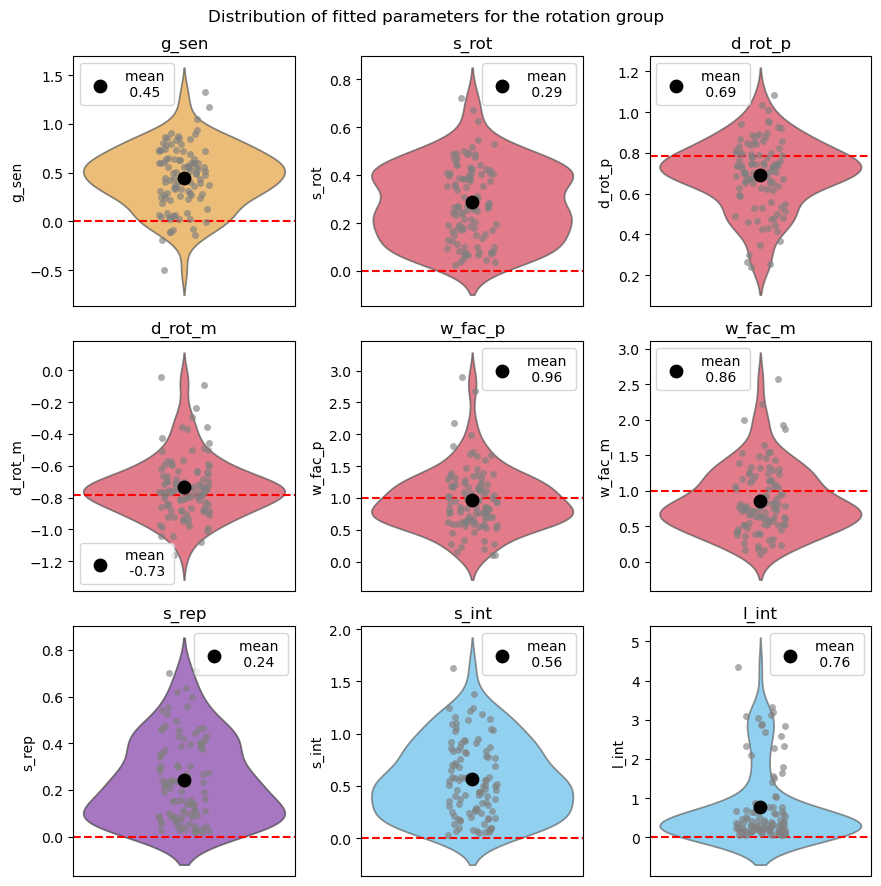

,param,mean,std,optimum,mean_diff,stat,p,signif
0,g_sen,0.448377,0.315454,0.000000,0.448377,150.0,5.938355e-17,***
1,s_rot,0.286068,0.157417,0.000000,0.286068,0.0,8.530138e-19,***
2,d_rot_p,0.693234,0.169923,0.785398,-0.092165,1218.0,9.432400e-07,***
3,d_rot_m,-0.733968,0.191827,-0.785398,0.051431,2043.0,2.589327e-02,*
4,w_fac_p,0.962028,0.481282,1.000000,-0.037972,2189.0,7.936904e-02,ns
5,w_fac_m,0.862662,0.462114,1.000000,-0.137338,1636.0,3.887119e-04,***
6,s_rep,0.242040,0.177314,0.000000,0.242040,0.0,8.530138e-19,***
7,s_int,0.562842,0.359346,0.000000,0.562842,0.0,8.530138e-19,***
8,l_int,0.762685,0.950853,0.000000,0.762685,0.0,8.530138e-19,***


In [16]:
plt.fig, axes = plt.subplots(3, 3, figsize=(9, 9))

ref_values = {
    "g_sen": 0,
    "s_rot": 0,
    "d_rot_p": np.deg2rad(45),
    "d_rot_m": np.deg2rad(-45),
    "w_fac_p": 1,
    "w_fac_m": 1,
    "s_int": 0,
    "l_int": 0,
    "s_rep": 0
}

for ax, param in zip(axes.flatten(), list(fitted_params_rotations.keys())):

    data = fitted_params_rotations[param]["average"]

    category = get_category(param)
    base_color = category_colors[category]

    # point_color = sns.light_palette(base_color, n_colors=3)[1]
    # line_color = sns.dark_palette(base_color, n_colors=3)[2]


    sns.violinplot(y=data, inner=None, color=base_color, ax=ax, alpha = 0.7)
    sns.stripplot(y=data, color="grey", alpha=0.65, ax=ax)

    mean = data.mean()
    ax.scatter(0, mean, color="black", s=80, zorder=3, label = f'mean \n {mean:.2f}')

    ref = ref_values[param]
    if ref is not None:
        ax.axhline(ref, color="red", linestyle="--")
        
    ax.set_ylabel(param)
    ax.set_xticks([])
    ax.set_title(param)
    ax.legend()

    plt.title(f"{param}")

plt.suptitle("Distribution of fitted parameters for the rotation group")
plt.tight_layout()
plt.show()


results = []

for param in fitted_params_rotations.keys():

    data = fitted_params_rotations[param]["average"]
    ref = ref_values[param]

    # différence à l'optimum
    diff = data - ref

    # test vs 0
    stat, p = wilcoxon(diff)

    results.append({
        "param": param,
        "mean": np.mean(data),
        "std": np.std(data),
        "optimum": ref,
        "mean_diff": np.mean(diff),
        "stat": stat,
        "p": p
    })

df_stats = pd.DataFrame(results)
def stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

df_stats["signif"] = df_stats["p"].apply(stars)
df_stats

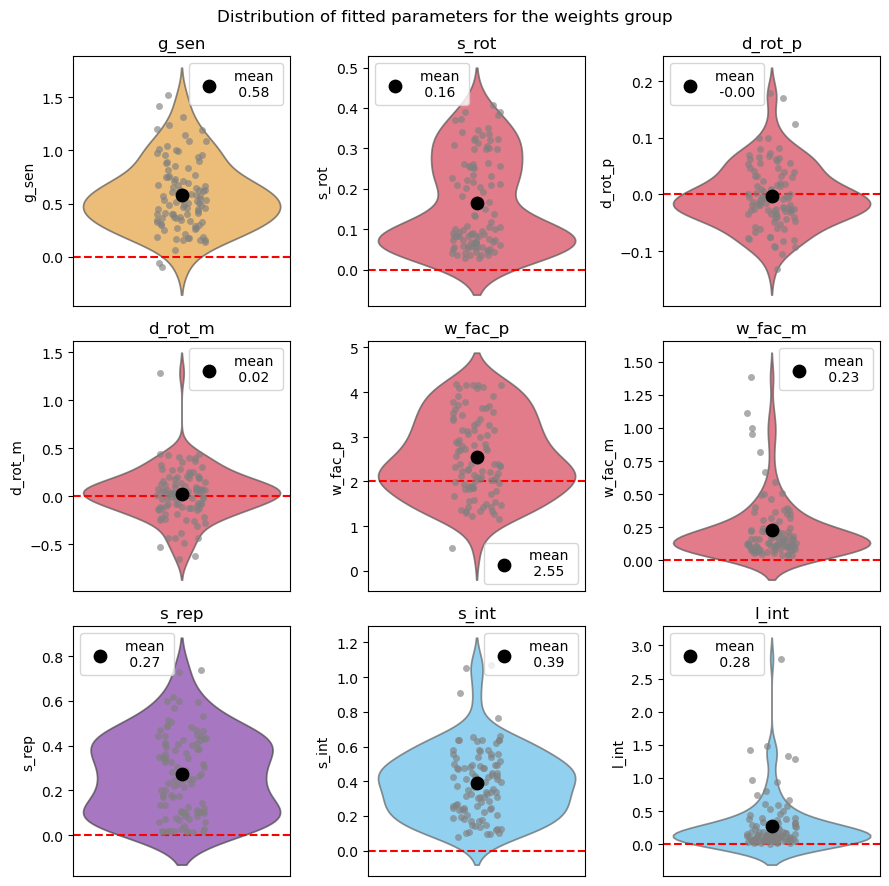

,param,mean,std,optimum,mean_diff,stat,p,signif
0,g_sen,0.579226,0.324500,0,0.579226,4.0,4.397114e-18,***
1,s_rot,0.164301,0.113866,0,0.164301,0.0,3.896560e-18,***
2,d_rot_p,-0.002607,0.055587,0,-0.002607,2223.0,2.990959e-01,ns
3,d_rot_m,0.023225,0.262517,0,0.023225,2217.0,2.895979e-01,ns
4,w_fac_p,2.553251,0.881811,2,0.553251,1036.0,3.060777e-07,***
5,w_fac_m,0.231060,0.230789,0,0.231060,0.0,3.896560e-18,***
6,s_rep,0.271439,0.181808,0,0.271439,0.0,3.896560e-18,***
7,s_int,0.389226,0.198032,0,0.389226,0.0,3.896560e-18,***
8,l_int,0.279923,0.395700,0,0.279923,0.0,3.896560e-18,***


In [17]:
plt.fig, axes = plt.subplots(3, 3, figsize=(9, 9))

ref_values = {
    "g_sen": 0,
    "s_rot": 0,
    "d_rot_p": 0,
    "d_rot_m": 0,
    "w_fac_p": 2,
    "w_fac_m": 0,
    "s_int": 0,
    "l_int": 0,
    "s_rep": 0
}

for ax, param in zip(axes.flatten(), list(fitted_params_weights.keys())):

    data = fitted_params_weights[param]["average"]

    category = get_category(param)
    base_color = category_colors[category]

    # point_color = sns.light_palette(base_color, n_colors=3)[1]
    # line_color = sns.dark_palette(base_color, n_colors=3)[2]


    sns.violinplot(y=data, inner=None, color=base_color, ax=ax, alpha = 0.7)
    sns.stripplot(y=data, color="grey", alpha=0.65, ax=ax)

    mean = data.mean()
    ax.scatter(0, mean, color="black", s=80, zorder=3, label = f'mean \n {mean:.2f}')

    ref = ref_values[param]
    if ref is not None:
        ax.axhline(ref, color="red", linestyle="--")
        
    ax.set_ylabel(param)
    ax.set_xticks([])
    ax.set_title(param)
    ax.legend()

    plt.title(f"{param}")

plt.suptitle("Distribution of fitted parameters for the weights group")
plt.tight_layout()
plt.show()


results = []

for param in fitted_params_weights.keys():

    data = fitted_params_weights[param]["average"]
    ref = ref_values[param]

    # différence à l'optimum
    diff = data - ref

    # test vs 0
    stat, p = wilcoxon(diff)

    results.append({
        "param": param,
        "mean": np.mean(data),
        "std": np.std(data),
        "optimum": ref,
        "mean_diff": np.mean(diff),
        "stat": stat,
        "p": p
    })

df_stats = pd.DataFrame(results)
def stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

df_stats["signif"] = df_stats["p"].apply(stars)
df_stats

                param  mean rot p  mean rot m  std rot p  std rot m    stat  \
0  d_rot_p vs d_rot_m    0.693234    0.733968   0.169923   0.191827  1768.0   

          p signif  
0  0.001811     **  


/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_94994/1667740499.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


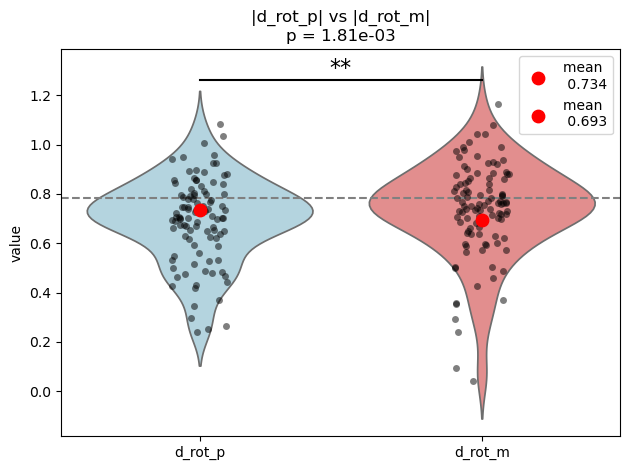

In [18]:
results = []

data_p = fitted_params_rotations["d_rot_p"]["average"].apply(np.abs)
data_m = fitted_params_rotations["d_rot_m"]["average"].apply(np.abs)
    
stat, p = wilcoxon(data_p, data_m)

results.append({
    "param": "d_rot_p vs d_rot_m",
    "mean rot p": np.mean(data_p),
    "mean rot m": np.mean(data_m),
    "std rot p": np.std(data_p),
    "std rot m": np.std(data_m),
    "stat": stat,
    "p": p
})


df_stats = pd.DataFrame(results)
def stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

sig = stars(p)
df_stats["signif"] = df_stats["p"].apply(stars)
print(df_stats)



df_plot = pd.DataFrame({
    "value": list(data_p) + list(data_m),
    "condition": ["d_rot_p"]*len(data_p) + ["d_rot_m"]*len(data_m)
})

sns.violinplot(
    data=df_plot,
    x="condition",
    y="value",
    inner=None,
    palette=["lightblue", "lightcoral"]
)

sns.stripplot(
    data=df_plot,
    x="condition",
    y="value",
    color="black",
    alpha=0.5
)

means = df_plot.groupby("condition")["value"].mean()

for i, m in enumerate(means):
    plt.scatter(i, m, color="red", s=80, zorder=3, label = f'mean \n {m:.3f}')
y_max = df_plot["value"].max()
y = y_max * 1.1 - 0.02


plt.axhline(np.deg2rad(45), color="grey", linestyle="--")
plt.plot([0, 1], [y, y], color='black')
plt.text(0.5, y, sig, ha='center', va='bottom', fontsize=16)
plt.ylabel("value")
plt.xlabel("")
plt.title(f"|d_rot_p| vs |d_rot_m|\np = {p:.2e}")

plt.tight_layout()
plt.legend()
plt.show()


### différences entre average et le mod

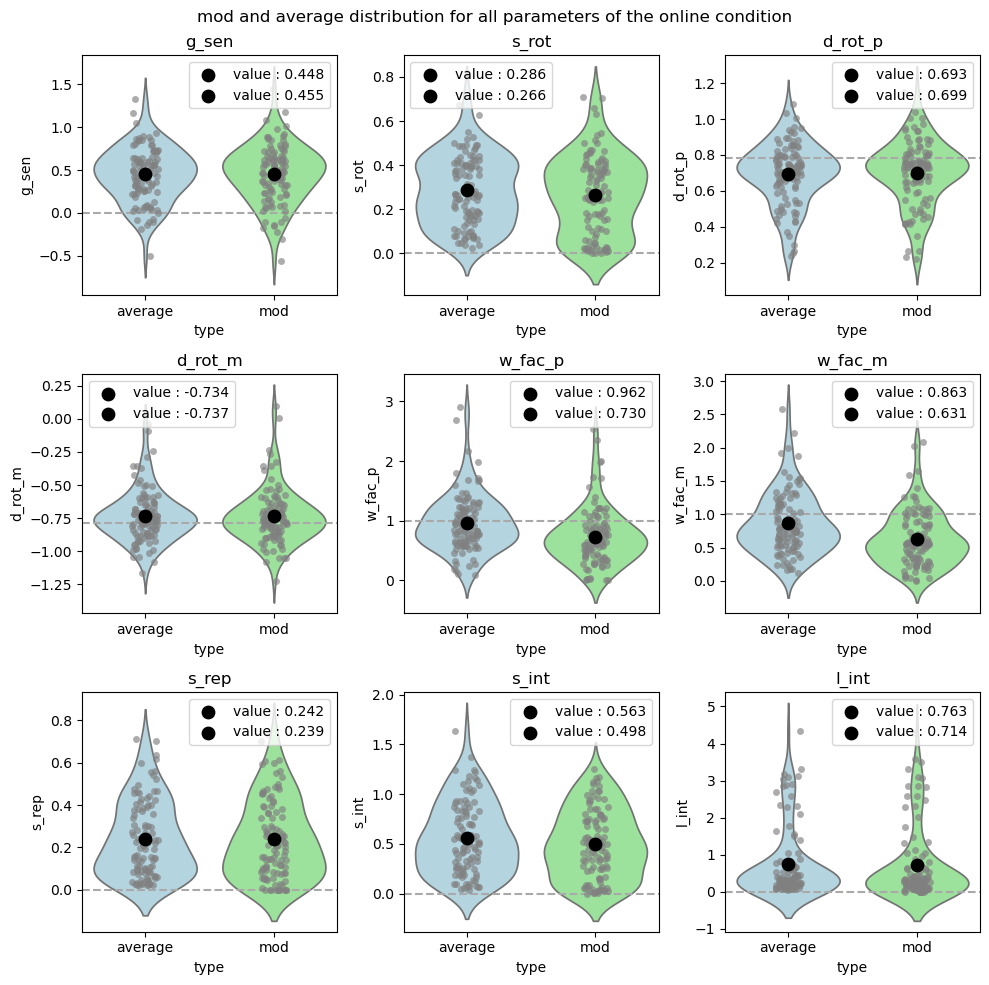

,g_sen,s_rot,d_rot_p,d_rot_m,w_fac_p,w_fac_m,s_rep,s_int,l_int
stat,2248.000000,1.116000e+03,2328.000000,2446.000000,1.280000e+02,6.000000e+01,1959.000000,4.560000e+02,9.710000e+02
p,0.118045,1.659782e-07,0.192367,0.357073,3.234080e-17,4.788695e-18,0.012412,1.654042e-13,1.169606e-08
mean_avg,0.448377,2.860681e-01,0.693234,-0.733968,9.620284e-01,8.626615e-01,0.242040,5.628424e-01,7.626855e-01
mean_mod,0.454875,2.659019e-01,0.698967,-0.736517,7.303036e-01,6.313495e-01,0.238864,4.979903e-01,7.143595e-01


In [19]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

ref_values = {
    "g_sen": 0,
    "s_rot": 0,
    "d_rot_p": np.deg2rad(45),
    "d_rot_m": np.deg2rad(-45),
    "w_fac_p": 1,
    "w_fac_m": 1,
    "s_int": 0,
    "l_int": 0,
    "s_rep": 0
}

for ax, param in zip(axes.flatten(), list(fitted_params_rotations.keys())):

    data = fitted_params_rotations[param]["average"]
    data2 = fitted_params_rotations[param]["mod"]

    df_plot = pd.DataFrame({
        "value": list(data) + list(data2),
        "type": ["average"]*len(data) + ["mod"]*len(data2)
    })

    sns.violinplot(data=df_plot, x="type", y="value", hue = "type", inner=None,
                palette=["lightblue", "lightgreen"], ax=ax, legend = False)

    sns.stripplot(data=df_plot, x="type", y="value",
                color="grey", alpha=0.65, ax=ax)

    means = df_plot.groupby("type")["value"].mean()

    for i, (group, m) in enumerate(means.items()):
        ax.scatter(i, m, color="black", s=80, zorder=3, label = f'value : {m:.3f}')
    
    ref = ref_values[param]
    if ref is not None:
        ax.axhline(ref, color="darkgrey", linestyle="--")
        
    ax.set_ylabel(param)
    ax.set_xticks([])
    ax.set_title(param)
    ax.set_xticks([0,1])
    ax.set_xticklabels(["average", "mod"])
    ax.legend()

plt.suptitle("mod and average distribution for all parameters of the online condition")
plt.tight_layout()
plt.legend()
plt.savefig("violin plot avg vs mod.pdf")
plt.show()


from scipy.stats import wilcoxon
from scipy.stats import ttest_rel

results = {}

for param in fitted_params_rotations.keys():
    data = fitted_params_rotations[param]["average"]
    data2 = fitted_params_rotations[param]["mod"]

    # stat, p = ttest_rel(data, data2)

    stat, p = wilcoxon(data, data2)

    results[param] = {
        "stat": stat,
        "p": p,
        "mean_avg": data.mean(),
        "mean_mod": data2.mean()
    }

pd.DataFrame(results)

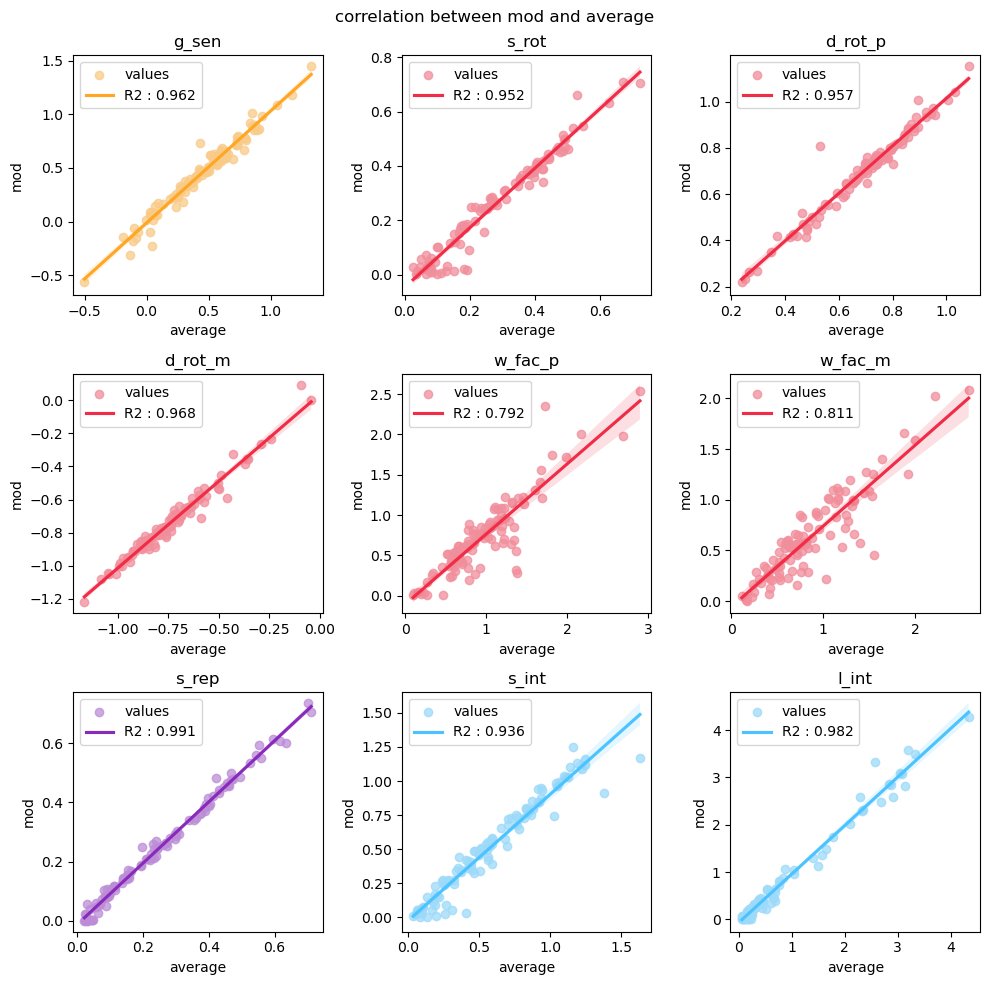

In [20]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for ax, param in zip(axes.flatten(), list(fitted_params_rotations.keys())):

    x = fitted_params_rotations[param]["average"]
    y = fitted_params_rotations[param]["mod"]
    
    slope, intercept, r_value, p_value, std_err = linregress(x, y)
    r2 = r_value**2

    category = get_category(param)
    base_color = category_colors[category]

    point_color = sns.light_palette(base_color, n_colors=3)[1],
    line_color = sns.light_palette(base_color, n_colors=3)[2]

    sns.regplot(x="average", y="mod", data = fitted_params_rotations[param], label = "values", scatter_kws={'alpha':0.75, 'color':point_color}, line_kws={"color": line_color, "label" : f"R2 : {r2:.3f}", "alpha" : 1 }, ax=ax)

    ax.legend()
    ax.set_title(param)
    
plt.suptitle("correlation between mod and average")
plt.tight_layout()
plt.legend()
plt.show()

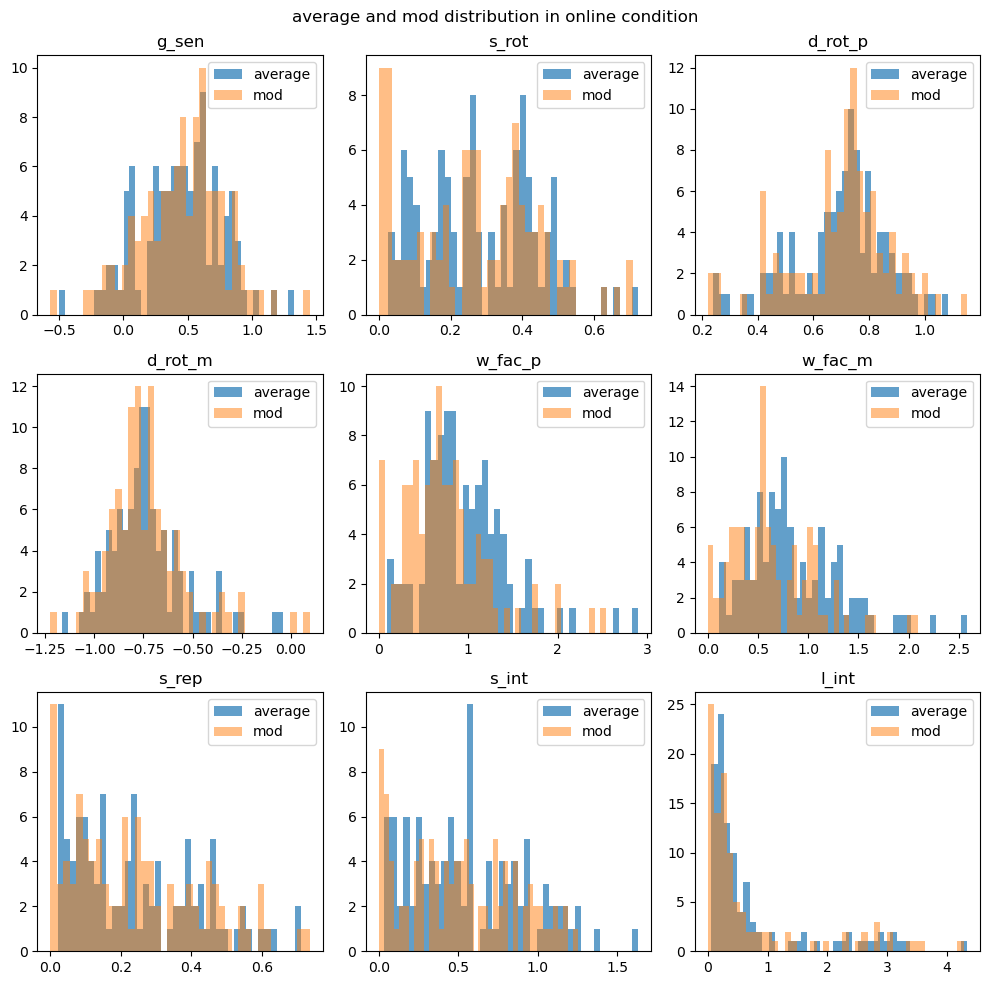

In [21]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for ax, (name, df) in zip(axes.flatten(), fitted_params_rotations.items()):
    
    ax.hist(df["average"], bins=40, alpha=0.7, label="average")
    ax.hist(df["mod"], bins=40, alpha=0.5, label="mod")
    
    ax.set_title(name)
    ax.legend()

plt.suptitle("average and mod distribution in online condition")
plt.tight_layout()
plt.show()

ONLINE VS IN LAB

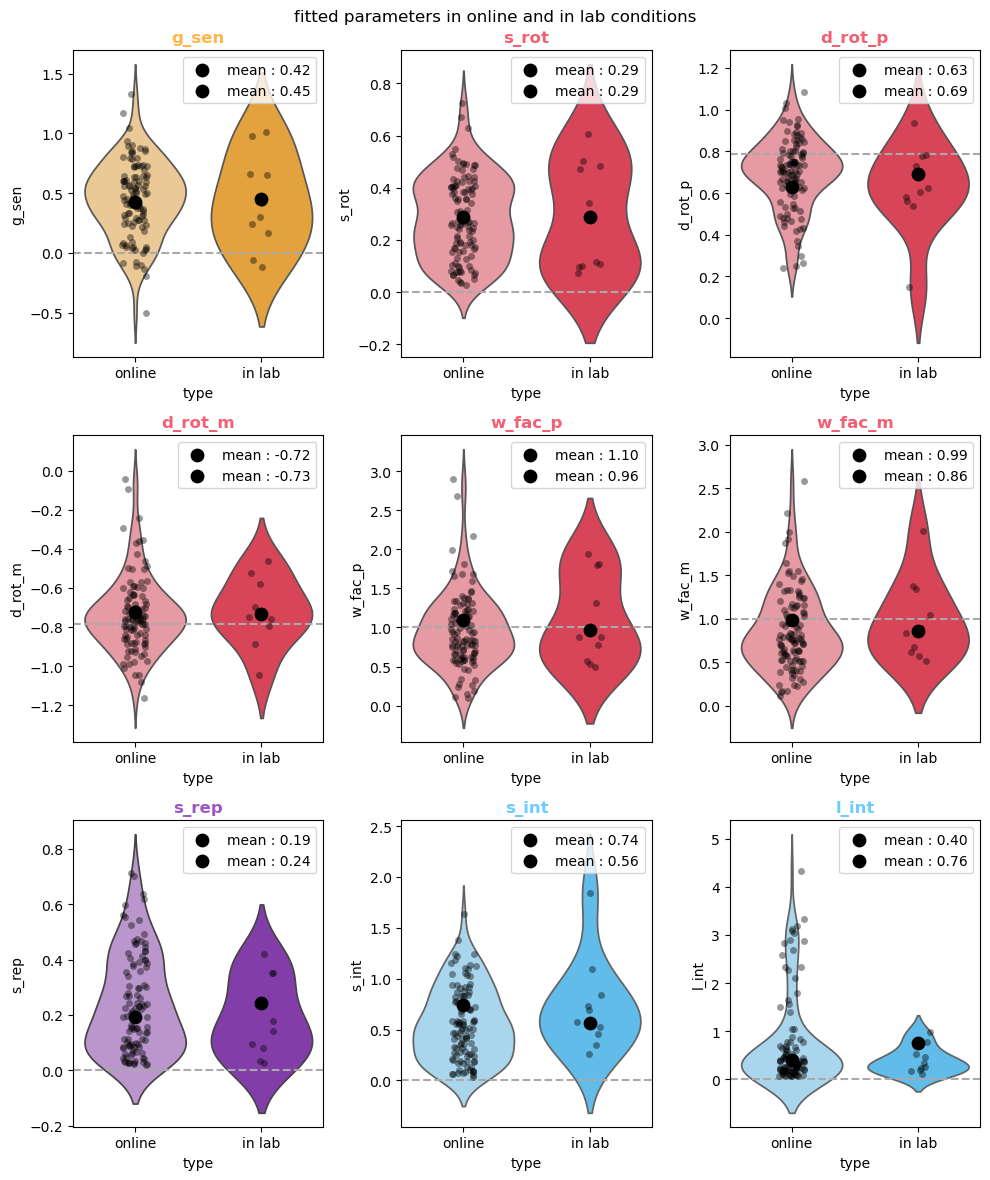

,g_sen,s_rot,d_rot_p,d_rot_m,w_fac_p,w_fac_m,s_rep,s_int,l_int
stat,2248.000000,1.116000e+03,2328.000000,2446.000000,1.280000e+02,6.000000e+01,1959.000000,4.560000e+02,9.710000e+02
p,0.118045,1.659782e-07,0.192367,0.357073,3.234080e-17,4.788695e-18,0.012412,1.654042e-13,1.169606e-08
mean_avg,0.448377,2.860681e-01,0.693234,-0.733968,9.620284e-01,8.626615e-01,0.242040,5.628424e-01,7.626855e-01
mean_mod,0.454875,2.659019e-01,0.698967,-0.736517,7.303036e-01,6.313495e-01,0.238864,4.979903e-01,7.143595e-01


In [22]:
fig, axes = plt.subplots(3, 3, figsize=(10, 12))

ref_values = {
    "g_sen": 0,
    "s_rot": 0,
    "d_rot_p": np.deg2rad(45),
    "d_rot_m": np.deg2rad(-45),
    "w_fac_p": 1,
    "w_fac_m": 1,
    "s_int": 0,
    "l_int": 0,
    "s_rep": 0
}

for ax, param in zip(axes.flatten(), list(fitted_params_rotations.keys())):

    data = fitted_params_rotations[param]["average"]
    data2 = fitted_params_inlab[param]["average"]

    df_plot = pd.DataFrame({
        "value": list(data) + list(data2),
        "type": ["online"]*len(data) + ["in lab"]*len(data2)
    })
    category = get_category(param)
    base_color = category_colors[category]

    palette = {
        "online": sns.light_palette(base_color, n_colors=3)[1],
        "in lab": sns.light_palette(base_color, n_colors=3)[2]}

    sns.violinplot(data=df_plot, x="type", y="value", hue = "type", inner=None,
                palette=palette, ax=ax, legend = False)

    sns.stripplot(data=df_plot, x="type", y="value",
                color="black", alpha=0.4, ax=ax)

    means = df_plot.groupby("type")["value"].mean()

    for i, (group, m) in enumerate(means.items()):
        ax.scatter(i, m, color="black", s=80, zorder=3, label = f'mean : {m:.2f}')
    
    ref = ref_values[param]
    if ref is not None:
        ax.axhline(ref, color="darkgrey", linestyle="--")
        
    ax.set_ylabel(param)
    ax.set_xticks([])
    ax.set_title(param, color=base_color, fontweight="bold")
    ax.set_xticks([0,1])
    ax.set_xticklabels(["online", "in lab"])
    ax.legend()
    

    
plt.suptitle("fitted parameters in online and in lab conditions")
plt.tight_layout()
plt.legend()
plt.savefig("violin plots online vs in lab.pdf")
plt.show()

from scipy.stats import wilcoxon
from scipy.stats import ttest_rel

results = {}

for param in fitted_params_rotations.keys():
    data = fitted_params_rotations[param]["average"]
    data2 = fitted_params_rotations[param]["mod"]

    # stat, p = ttest_rel(data, data2)

    stat, p = wilcoxon(data, data2)

    results[param] = {
        "stat": stat,
        "p": p,
        "mean_avg": data.mean(),
        "mean_mod": data2.mean()
    }

pd.DataFrame(results)

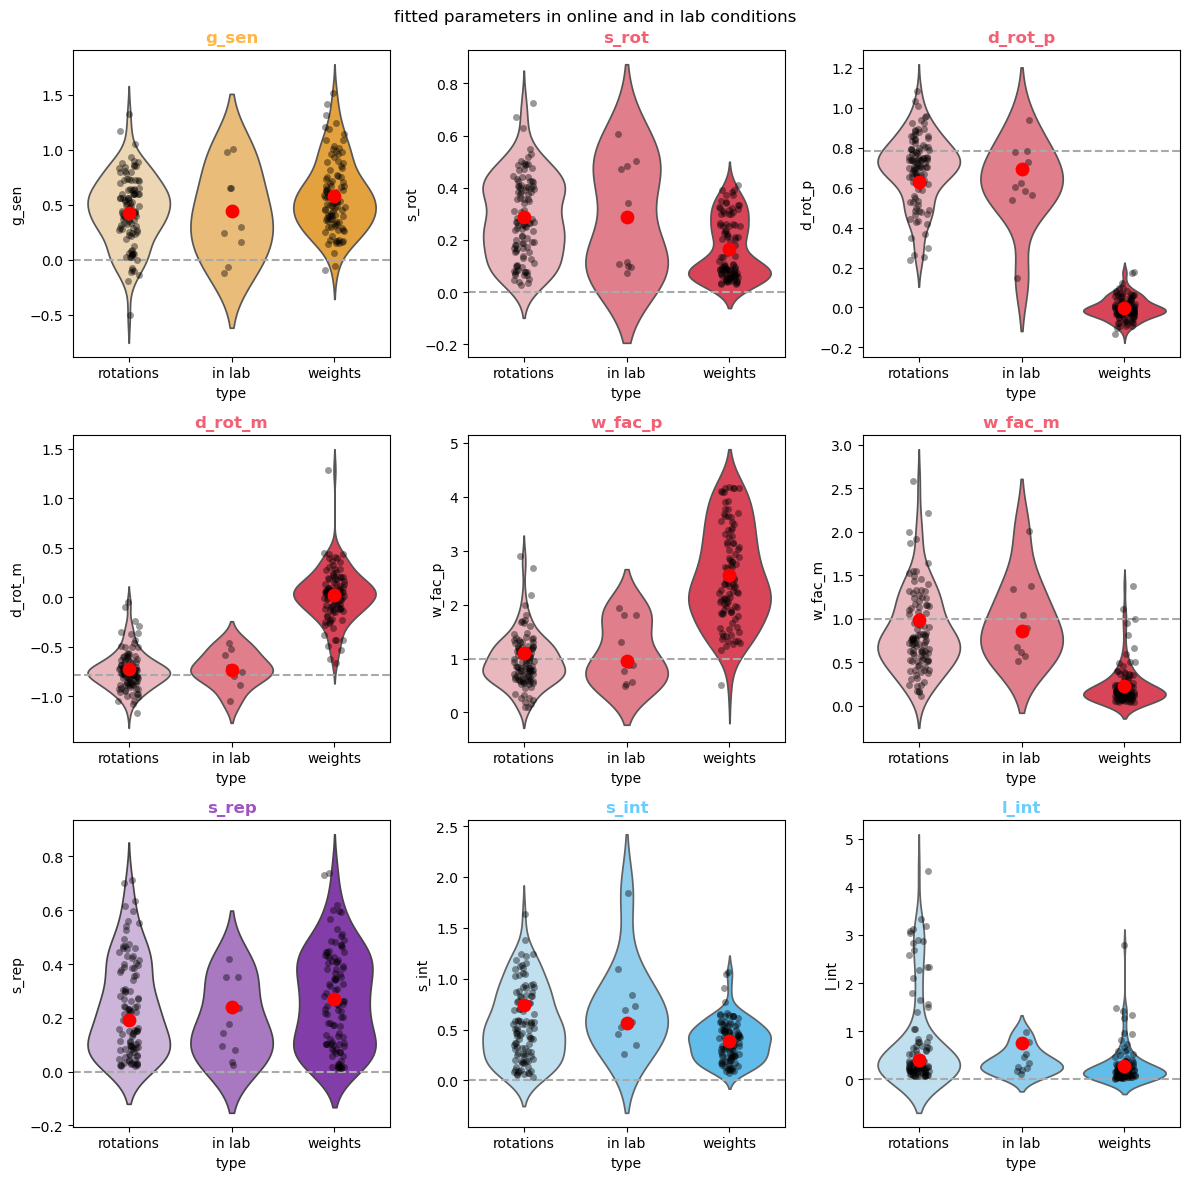

In [23]:
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

ref_values = {
    "g_sen": 0,
    "s_rot": 0,
    "d_rot_p": np.deg2rad(45),
    "d_rot_m": np.deg2rad(-45),
    "w_fac_p": 1,
    "w_fac_m": 1,
    "s_int": 0,
    "l_int": 0,
    "s_rep": 0
}
positions = [0, 1, 2.3]

for ax, param in zip(axes.flatten(), list(fitted_params_rotations.keys())):

    data = fitted_params_rotations[param]["average"]
    data2 = fitted_params_inlab[param]["average"]
    data3 = fitted_params_weights[param]["average"]

    df_plot = pd.DataFrame({
        "value": list(data) + list(data2) + list(data3),
        "type": ["rotations"]*len(data) + ["in lab"]*len(data2) + ["weights"]*len(data3)
    })
    category = get_category(param)
    base_color = category_colors[category]

    palette = {
        "rotations": sns.light_palette(base_color, n_colors=4)[1],
        "in lab": sns.light_palette(base_color, n_colors=4)[2],
        "weights": sns.light_palette(base_color, n_colors=4)[3]}

    sns.violinplot(data=df_plot, x="type", y="value", hue = "type", inner=None,
                palette=palette, ax=ax, legend = False)
    

    sns.stripplot(data=df_plot, x="type", y="value",
                color="black", alpha=0.4, ax=ax)

    means = df_plot.groupby("type")["value"].mean()

    for i, (group, m) in enumerate(means.items()):
        ax.scatter(i, m, color="red", s=80, zorder=3, label = f'mean : {m:.2f}')
    
    ref = ref_values[param]
    if ref is not None:
        ax.axhline(ref, color="darkgrey", linestyle="--")
        
    ax.set_ylabel(param)
    ax.set_xticks([])
    ax.set_title(param, color=base_color, fontweight="bold")
    ax.set_xticks([0,1,2])
    ax.set_xticklabels(["rotations", "in lab", "weights"])
    # ax.legend()
    

    
plt.suptitle("fitted parameters in online and in lab conditions")
plt.tight_layout()

# plt.legend()
# plt.savefig("violin plots online vs in lab.pdf")
plt.show()


In [24]:
ref_values = {
    "g_sen": 0,
    "s_rot": 0,
    "d_rot_p": np.deg2rad(45),
    "d_rot_m": np.deg2rad(-45),
    "w_fac_p": 1,
    "w_fac_m": 1,
    "s_int": 0,
    "l_int": 0,
    "s_rep": 0
}

without_rot_weights = ["g_sen", "s_rot", "s_int", "l_int", "s_rep"]
rotation_parameters = ["d_rot_p", "d_rot_m"]
weights_parameters = ["w_fac_p", "w_fac_m"]

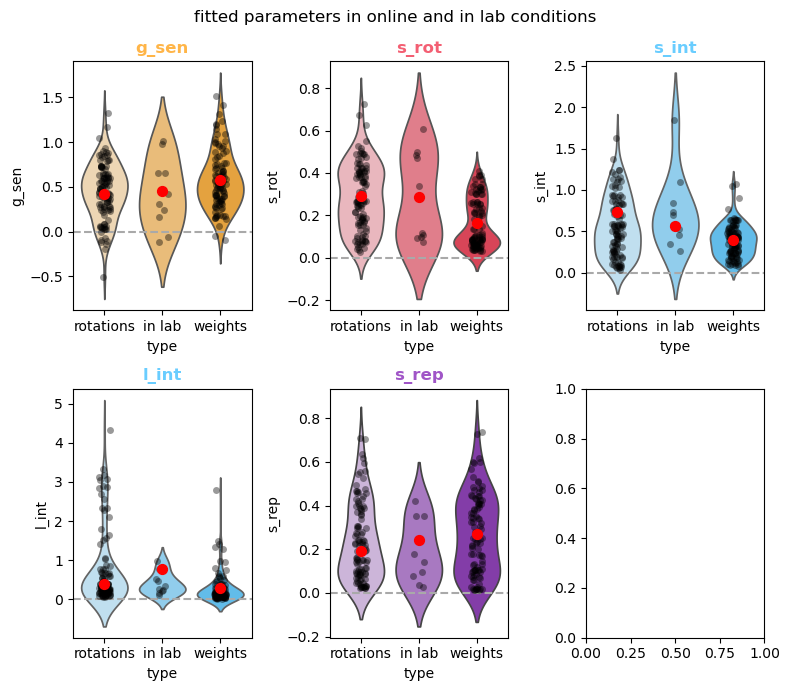

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(8, 7))

for ax, param in zip(axes.flatten(), without_rot_weights) :

    data = fitted_params_rotations[param]["average"]
    data2 = fitted_params_inlab[param]["average"]
    data3 = fitted_params_weights[param]["average"]

    df_plot = pd.DataFrame({
        "value": list(data) + list(data2) + list(data3),
        "type": ["rotations"]*len(data) + ["in lab"]*len(data2) + ["weights"]*len(data3)
    })
    category = get_category(param)
    base_color = category_colors[category]

    palette = {
        "rotations": sns.light_palette(base_color, n_colors=4)[1],
        "in lab": sns.light_palette(base_color, n_colors=4)[2],
        "weights": sns.light_palette(base_color, n_colors=4)[3]}

    sns.violinplot(data=df_plot, x="type", y="value", hue = "type", inner=None,
                palette=palette, ax=ax, legend = False)
    

    sns.stripplot(data=df_plot, x="type", y="value",
                color="black", alpha=0.4, ax=ax)

    means = df_plot.groupby("type")["value"].mean()

    for i, (group, m) in enumerate(means.items()):
        ax.scatter(i, m, color="red", s=50, zorder=3, label = f'mean : {m:.2f}')
    
    ref = ref_values[param]
    if ref is not None:
        ax.axhline(ref, color="darkgrey", linestyle="--")
        
    ax.set_ylabel(param)
    ax.set_xticks([])
    ax.set_title(param, color=base_color, fontweight="bold")
    ax.set_xticks([0,1,2])
    ax.set_xticklabels(["rotations", "in lab", "weights"])
    # ax.legend()
    

    
plt.suptitle("fitted parameters in online and in lab conditions")
plt.tight_layout()

# plt.legend()
# plt.savefig("violin plots online vs in lab.pdf")
plt.show()


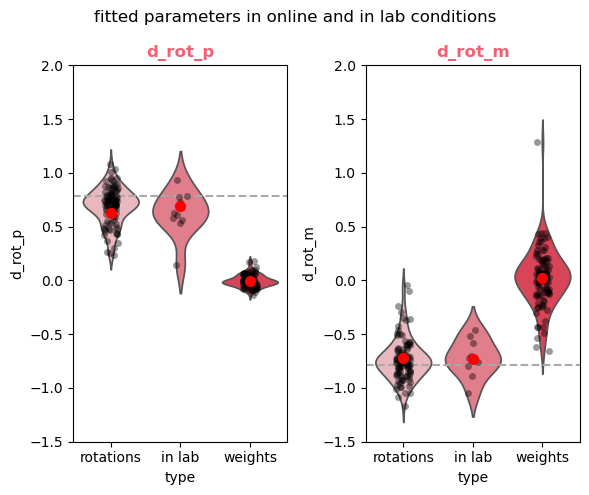

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(6, 5))

for ax, param in zip(axes.flatten(), rotation_parameters) :

    data = fitted_params_rotations[param]["average"]
    data2 = fitted_params_inlab[param]["average"]
    data3 = fitted_params_weights[param]["average"]

    df_plot = pd.DataFrame({
        "value": list(data) + list(data2) + list(data3),
        "type": ["rotations"]*len(data) + ["in lab"]*len(data2) + ["weights"]*len(data3)
    })
    category = get_category(param)
    base_color = category_colors[category]

    palette = {
        "rotations": sns.light_palette(base_color, n_colors=4)[1],
        "in lab": sns.light_palette(base_color, n_colors=4)[2],
        "weights": sns.light_palette(base_color, n_colors=4)[3]}

    sns.violinplot(data=df_plot, x="type", y="value", hue = "type", inner=None,
                palette=palette, ax=ax, legend = False)
    

    sns.stripplot(data=df_plot, x="type", y="value",
                color="black", alpha=0.4, ax=ax)

    means = df_plot.groupby("type")["value"].mean()

    for i, (group, m) in enumerate(means.items()):
        ax.scatter(i, m, color="red", s=50, zorder=3, label = f'mean : {m:.2f}')
    
    ref = ref_values[param]
    if ref is not None:
        ax.axhline(ref, color="darkgrey", linestyle="--")
    ax.set_ylim(-1.5, 2)
    ax.set_ylabel(param)
    ax.set_xticks([])
    ax.set_title(param, color=base_color, fontweight="bold")
    ax.set_xticks([0,1,2])
    ax.set_xticklabels(["rotations", "in lab", "weights"])
    # ax.legend()
    

    
plt.suptitle("fitted parameters in online and in lab conditions")
plt.tight_layout()

# plt.legend()
# plt.savefig("violin plots online vs in lab.pdf")
plt.savefig("figure.pdf", dpi=300, bbox_inches="tight")
plt.show()


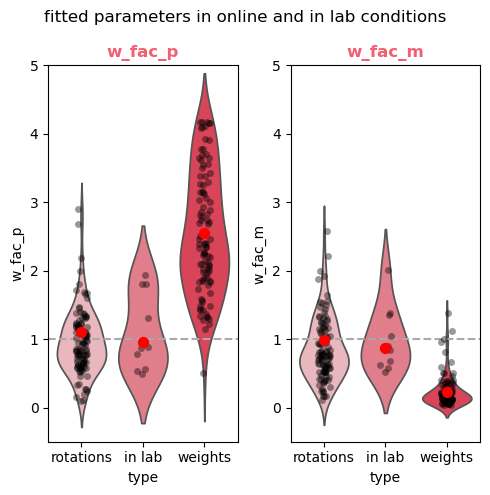

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(5, 5))

for ax, param in zip(axes.flatten(), weights_parameters) :

    data = fitted_params_rotations[param]["average"]
    data2 = fitted_params_inlab[param]["average"]
    data3 = fitted_params_weights[param]["average"]

    df_plot = pd.DataFrame({
        "value": list(data) + list(data2) + list(data3),
        "type": ["rotations"]*len(data) + ["in lab"]*len(data2) + ["weights"]*len(data3)
    })
    category = get_category(param)
    base_color = category_colors[category]

    palette = {
        "rotations": sns.light_palette(base_color, n_colors=4)[1],
        "in lab": sns.light_palette(base_color, n_colors=4)[2],
        "weights": sns.light_palette(base_color, n_colors=4)[3]}

    sns.violinplot(data=df_plot, x="type", y="value", hue = "type", inner=None,
                palette=palette, ax=ax, legend = False)
    

    sns.stripplot(data=df_plot, x="type", y="value",
                color="black", alpha=0.4, ax=ax)

    means = df_plot.groupby("type")["value"].mean()

    for i, (group, m) in enumerate(means.items()):
        ax.scatter(i, m, color="red", s=50, zorder=3, label = f'mean : {m:.2f}')
    
    ref = ref_values[param]
    if ref is not None:
        ax.axhline(ref, color="darkgrey", linestyle="--")
        
    ax.set_ylim(-0.5, 5)
    ax.set_ylabel(param)
    ax.set_xticks([])
    ax.set_title(param, color=base_color, fontweight="bold")
    ax.set_xticks([0,1,2])
    ax.set_xticklabels(["rotations", "in lab", "weights"])
    # ax.legend()
    

    
plt.suptitle("fitted parameters in online and in lab conditions")
plt.tight_layout()

# plt.legend()
# plt.savefig("violin plots online vs in lab.pdf")
# plt.show()
plt.savefig("figure.pdf", dpi=300, bbox_inches="tight")